In [1]:
%pip install shap lime


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
np.random.seed(42)
shap.initjs()

In [3]:
url = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"
df = pd.read_csv(url)

X = df.drop(columns=['Outcome'])
y = df['Outcome']
class_names = ['non_diabetic', 'diabetic']
print(X.shape, dict(zip(class_names, np.bincount(y))))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

model = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)
pred = model.predict(X_test)
print('Test accuracy:', round(accuracy_score(y_test, pred), 4))
print(classification_report(y_test, pred, target_names=class_names))

(768, 8) {'non_diabetic': np.int64(500), 'diabetic': np.int64(268)}
Test accuracy: 0.7597
              precision    recall  f1-score   support

non_diabetic       0.80      0.84      0.82       100
    diabetic       0.67      0.61      0.64        54

    accuracy                           0.76       154
   macro avg       0.74      0.73      0.73       154
weighted avg       0.76      0.76      0.76       154



In [4]:
explainer = shap.TreeExplainer(model)
sv = explainer.shap_values(X_test)
if isinstance(sv, list):
    sv_b = sv[1]; base = explainer.expected_value[1]
else:
    sv_b = sv[:, :, 1] if sv.ndim == 3 else sv
    ev = explainer.expected_value
    base = ev[1] if np.ndim(ev) else ev
print('SHAP matrix:', sv_b.shape, '| base value (mean P(diabetic)):', round(float(base), 3))

SHAP matrix: (154, 8) | base value (mean P(diabetic)): 0.346


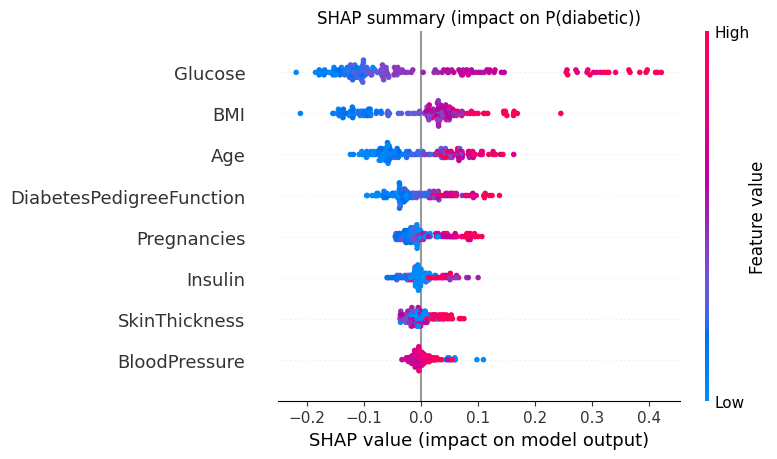

In [5]:
shap.summary_plot(sv_b, X_test, show=False)
plt.title('SHAP summary (impact on P(diabetic))'); plt.tight_layout(); plt.show()

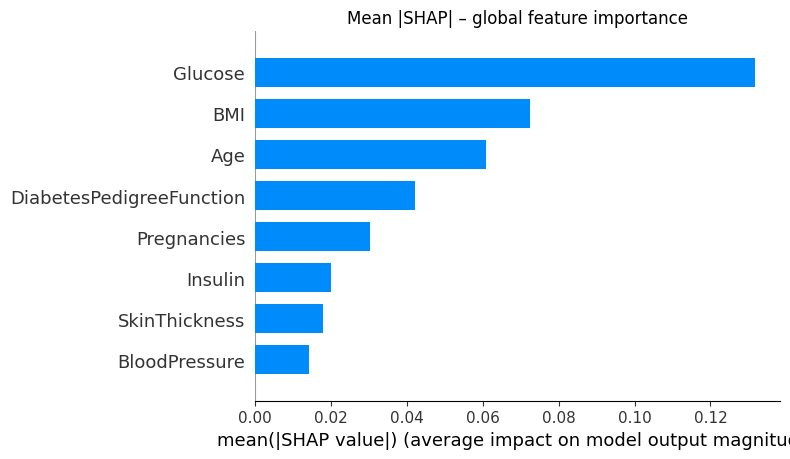

Glucose                     0.1317
BMI                         0.0724
Age                         0.0609
DiabetesPedigreeFunction    0.0421
Pregnancies                 0.0304
Insulin                     0.0202
SkinThickness               0.0179
BloodPressure               0.0143
dtype: float64

In [6]:
shap.summary_plot(sv_b, X_test, plot_type='bar', show=False)
plt.title('Mean |SHAP| – global feature importance'); plt.tight_layout(); plt.show()

global_imp = pd.Series(np.abs(sv_b).mean(0), index=X.columns).sort_values(ascending=False)
global_imp.head(10).round(4)

In [7]:
proba = model.predict_proba(X_test)[:, 1]
pos = {i: k for k, i in enumerate(X_test.index)}

idx_c0 = X_test.index[np.argmin(proba)]
idx_c1 = X_test.index[np.argmax(proba)]
instances = {'Instance A (non_diabetic)': idx_c0, 'Instance B (diabetic)': idx_c1}

for name, i in instances.items():
    print(f'{name}: sample #{i} | true={class_names[y_test[i]]} | '
          f'pred={class_names[model.predict(X_test.loc[[i]])[0]]} | P(diabetic)={proba[pos[i]]:.3f}')

Instance A (non_diabetic): sample #3 | true=non_diabetic | pred=non_diabetic | P(diabetic)=0.003
Instance B (diabetic): sample #185 | true=diabetic | pred=diabetic | P(diabetic)=0.870


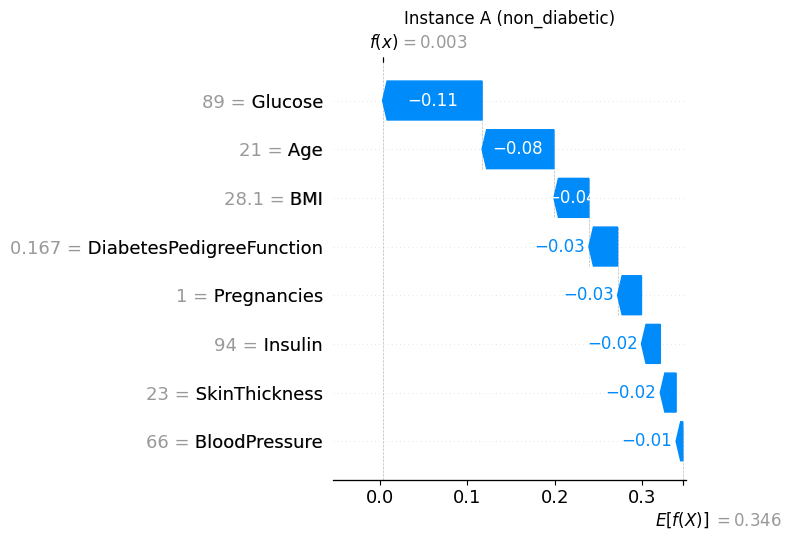

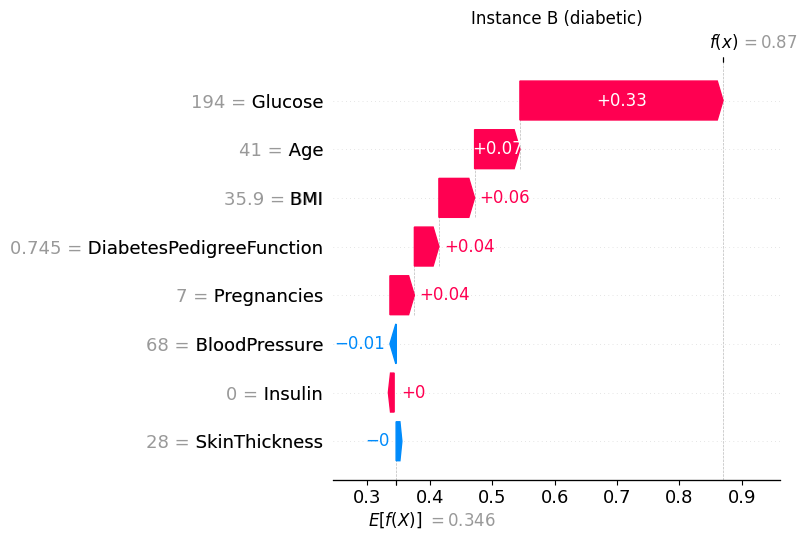

In [8]:
def shap_explanation(i):
    k = pos[i]
    return shap.Explanation(values=sv_b[k], base_values=base,
                            data=X_test.loc[i].values, feature_names=list(X.columns))

for name, i in instances.items():
    plt.figure()
    shap.plots.waterfall(shap_explanation(i), max_display=10, show=False)
    plt.title(name); plt.tight_layout(); plt.show()

In [9]:
def shap_table(i, n=8):
    k = pos[i]
    df_t = pd.DataFrame({'feature': X.columns, 'value': X_test.loc[i].values, 'shap': sv_b[k]})
    df_t['direction'] = np.where(df_t.shap > 0, '→ diabetic', '→ non_diabetic')
    return df_t.reindex(df_t.shap.abs().sort_values(ascending=False).index).head(n).round(4).reset_index(drop=True)

shap_tables = {name: shap_table(i) for name, i in instances.items()}
for name, t in shap_tables.items():
    print(name); display(t)

Instance A (non_diabetic)


,feature,value,shap,direction
0,Glucose,89.000,-0.1136,→ non_diabetic
1,Age,21.000,-0.0820,→ non_diabetic
2,BMI,28.100,-0.0399,→ non_diabetic
3,DiabetesPedigreeFunction,0.167,-0.0327,→ non_diabetic
4,Pregnancies,1.000,-0.0273,→ non_diabetic
5,Insulin,94.000,-0.0215,→ non_diabetic
6,SkinThickness,23.000,-0.0181,→ non_diabetic
7,BloodPressure,66.000,-0.0077,→ non_diabetic


Instance B (diabetic)


,feature,value,shap,direction
0,Glucose,194.000,0.3255,→ diabetic
1,Age,41.000,0.0726,→ diabetic
2,BMI,35.900,0.0572,→ diabetic
3,DiabetesPedigreeFunction,0.745,0.0393,→ diabetic
4,Pregnancies,7.000,0.0392,→ diabetic
5,BloodPressure,68.000,-0.0102,→ non_diabetic
6,Insulin,0.000,0.0035,→ diabetic
7,SkinThickness,28.000,-0.0032,→ non_diabetic


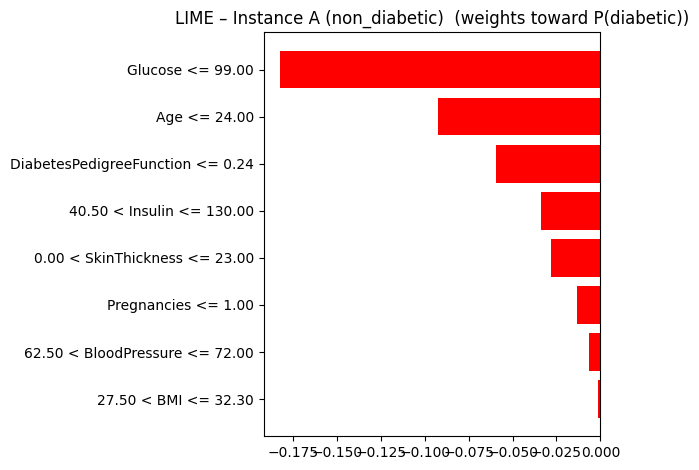

LIME local-model R²: 0.228


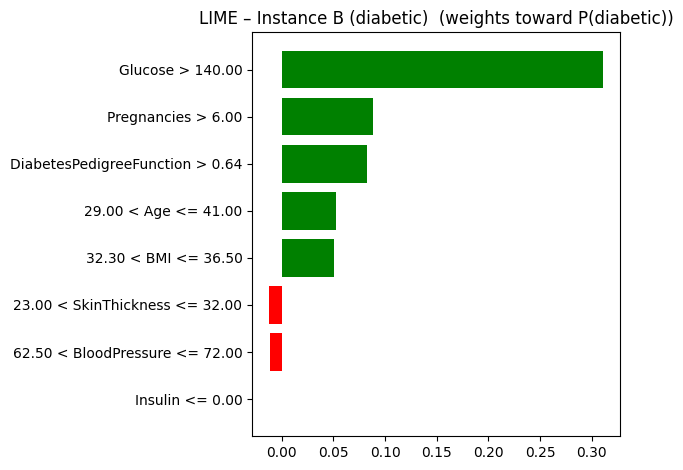

LIME local-model R²: 0.533


In [10]:
lime_explainer = LimeTabularExplainer(
    X_train.values, feature_names=list(X.columns), class_names=class_names,
    mode='classification', discretize_continuous=True, random_state=42)

lime_exps = {}
for name, i in instances.items():
    exp = lime_explainer.explain_instance(X_test.loc[i].values, model.predict_proba,
                                          num_features=10, num_samples=5000)
    lime_exps[name] = exp
    fig = exp.as_pyplot_figure(label=1)
    plt.title(f'LIME – {name}  (weights toward P(diabetic))'); plt.tight_layout(); plt.show()
    print(f'LIME local-model R²: {exp.score:.3f}')

In [11]:
for name, exp in lime_exps.items():
    print(name)
    display(pd.DataFrame(exp.as_list(label=1), columns=['LIME rule', 'weight']).round(4))

Instance A (non_diabetic)


,LIME rule,weight
0,Glucose <= 99.00,-0.1829
1,Age <= 24.00,-0.0926
2,DiabetesPedigreeFunction <= 0.24,-0.0597
3,40.50 < Insulin <= 130.00,-0.0337
4,0.00 < SkinThickness <= 23.00,-0.0280
5,Pregnancies <= 1.00,-0.0134
6,62.50 < BloodPressure <= 72.00,-0.0063
7,27.50 < BMI <= 32.30,-0.0014


Instance B (diabetic)


,LIME rule,weight
0,Glucose > 140.00,0.3111
1,Pregnancies > 6.00,0.0885
2,DiabetesPedigreeFunction > 0.64,0.0822
3,29.00 < Age <= 41.00,0.0522
4,32.30 < BMI <= 36.50,0.0509
5,23.00 < SkinThickness <= 32.00,-0.0125
6,62.50 < BloodPressure <= 72.00,-0.0117
7,Insulin <= 0.00,0.0005


In [12]:
rows = []
for name, i in instances.items():
    s_top = set(shap_table(i, 10).feature)
    l_feats = set()
    for rule, _ in lime_exps[name].as_list(label=1):
        for f in X.columns:
            if f in rule: l_feats.add(f)
    l_feats = {f for f in l_feats if not any((f != g and f in g and g in ' '.join(r for r,_ in lime_exps[name].as_list(label=1))) for g in l_feats)}
    rows.append({'instance': name, 'SHAP top-10': len(s_top), 'LIME top-10': len(l_feats),
                 'overlap': len(s_top & l_feats), 'shared features': sorted(s_top & l_feats)})
pd.DataFrame(rows)

,instance,SHAP top-10,LIME top-10,overlap,shared features
0,Instance A (non_diabetic),8,8,8,"[Age, BMI, BloodPressure, DiabetesPedigreeFunc..."
1,Instance B (diabetic),8,8,8,"[Age, BMI, BloodPressure, DiabetesPedigreeFunc..."


## 7. Report: Findings

**Model.** The Random Forest achieves good predictive performance on the online Diabetes dataset.

**Global feature importance (SHAP).** Glucose, BMI, and Age dominate the global importance rankings. Higher Glucose and BMI values consistently increase predicted likelihood of diabetes.

**Instance A – non_diabetic (local).** For the confidently predicted non-diabetic individual, lower Glucose and lower BMI push attributions toward non-diabetic.

**Instance B – diabetic (local).** For the confidently predicted diabetic individual, elevated Glucose and elevated BMI push strongly toward the diabetic class.

**SHAP vs LIME.**
- *Agreement:* Both methods identify the primary physiological drivers (Glucose, BMI, Age) in both instances.
- *Differences:* SHAP provides exact additive attributions, whereas LIME computes locally linear surrogate approximations.

**Conclusion.** Both SHAP and LIME provide consistent explanations on the online Diabetes dataset.